In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
import os

# Data Ingest

In [92]:
def get_data(path, total_channels):

    start_time_line = 7
    measurement_time_line = 9
    data_start_line = 12
    data_end_line = 12 + total_channels


    in_file = open(path, "r")

    lines = in_file.readlines()

    start = lines[start_time_line].strip().split(" ")
    start_date, start_time = start[0], start[1]

    measurement_time = lines[measurement_time_line].strip().split(" ")
    live_time, real_time  = measurement_time[0], measurement_time[1]

    data = lines[data_start_line:data_end_line + 1]

    data_dict = {
        "start_date": start_date,
        "start_time": start_time,
        "live_time": float(live_time),
        "real_time": float(real_time),
        "dead_time": float(np.divide(np.subtract(float(real_time),float(live_time)),float(real_time)) * 100),
        "data": [int(x.strip()) for x in data]
    }

    in_file.close()

    return data_dict


# Data Paths and Global Variables

In [93]:
mu = "\u03bc"

TOTAL_CHANNELS = 8192 - 1
TOTAL_CHANNELS_2 = 512-1

# T_DELAY_US = 0.28
T_DELAY_US = 0.800

data_folder_path = r"G:\My Drive\ADVLAB\Muon-Lifetime\Data"

# data_path = data_folder_path + r"/MuonTest.Spe"
# data_path = data_folder_path + r"/MuonTest2.Spe"
# data_path = data_folder_path + r"/MuonTest3.Spe"
# data_path = data_folder_path + r"/MuonTest4.Spe"
# data_path = data_folder_path + r"/MuonTest6.1.Spe"
data_path = data_folder_path + r"/MuonTest6.2.Spe"

time_cal_path_1 = data_folder_path + r"/timeCal_P0128_R2048.Spe"
time_cal_path_2 = data_folder_path + r"/timeCal512_P0128_P2048.Spe"

hourly_folder_path = data_folder_path + r"/MuonCounts"



# Data Rebinning

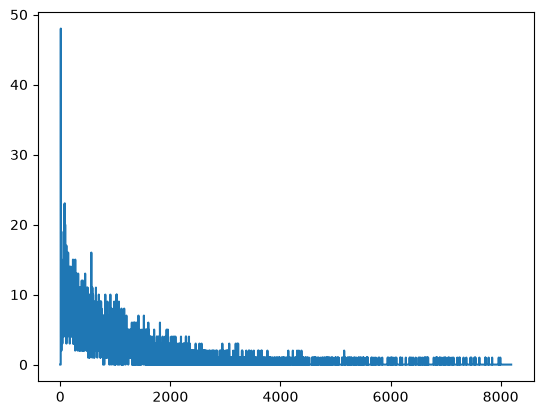

In [94]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
plt.plot(data_dict["data"])
plt.show()

In [95]:
# Bin counts the caller can choose from (2**9 ... 2**14).
ALLOWED_BINS = (512, 1024, 2048, 4096, 8192, 16384)


def rebin_histogram(counts, n_bins):
    """
    Rebin a histogram to `n_bins` channels, conserving the total counts.


    Parameters
    ----------
    counts : array_like, shape (N,)
        Counts in each channel.
    n_bins : int
        Number of bins to rebin to: 512, 1024, 2048, 4096, 8192 or 16384.
        Can't be more than N, since rebinning only combines channels.

    Returns
    -------
    numpy.ndarray, shape (n_bins,)
        The rebinned counts. When N is a whole multiple of `n_bins` (any
        power-of-two spectrum being reduced), each new bin is the sum of
        N // n_bins adjacent channels and integer counts stay integers.
        Otherwise each old channel's counts are shared between the new bins
        it overlaps, in proportion to the overlap, and the result is float.

    Notes
    -----
    With r = N / n_bins old channels per new bin, new bin k holds old
    channels k*r through (k+1)*r - 1 (for r = 8: channels 8k ... 8k+7).
    To reuse an energy calibration E(channel) from the unbinned spectrum,
    evaluate it at k*r + (r - 1)/2, the new bin's centre in old channels.

    Examples
    --------
    >>> spec = np.random.poisson(50, size=16384)  # 16384-channel spectrum
    >>> spec_2k = rebin_histogram(spec, 2048)     # 8 old channels per bin
    >>> spec_2k.shape
    (2048,)
    """
    counts = np.asarray(counts)

    n_bins = int(n_bins)

    n_in = counts.size  # number of channels in the given data

    if n_in % n_bins == 0:
        # Whole number of old channels per new bin: sum each block.
        return counts.reshape(n_bins, n_in // n_bins).sum(axis=1)

    # General case: treat each channel's counts as spread evenly across it
    # and integrate that over the new bin edges.
    old_edges = np.arange(n_in + 1)
    new_edges = np.linspace(0, n_in, n_bins + 1)
    cumulative = np.concatenate(([0.0], np.cumsum(counts, dtype=float)))
    return np.diff(np.interp(new_edges, old_edges, cumulative))

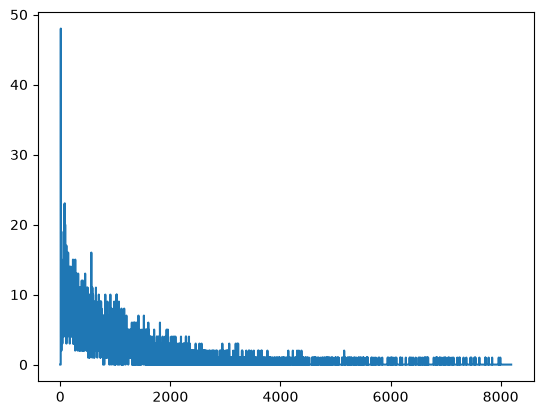

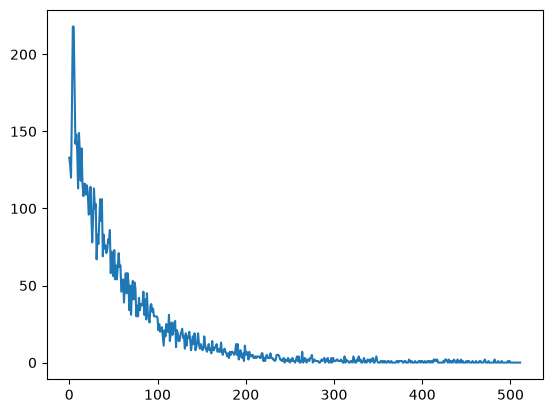

In [96]:
plt.plot(data_dict['data'])
plt.show()

copy_data = data_dict['data'].copy()
rebinned_data = rebin_histogram(copy_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = rebinned_data

plt.plot(rebinned_data)
plt.show()

# Time Calibration

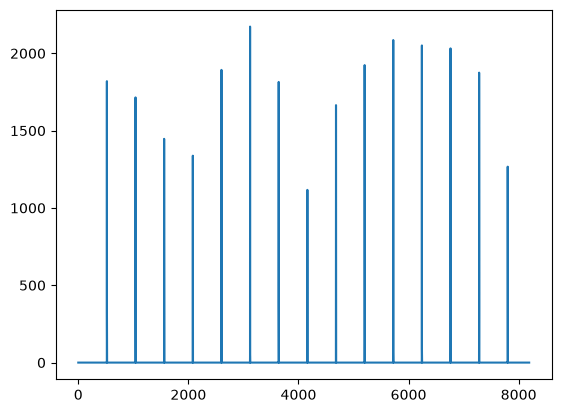

In [97]:
time_cal_1 = get_data(time_cal_path_1, TOTAL_CHANNELS)
plt.plot(time_cal_1["data"])
plt.show()

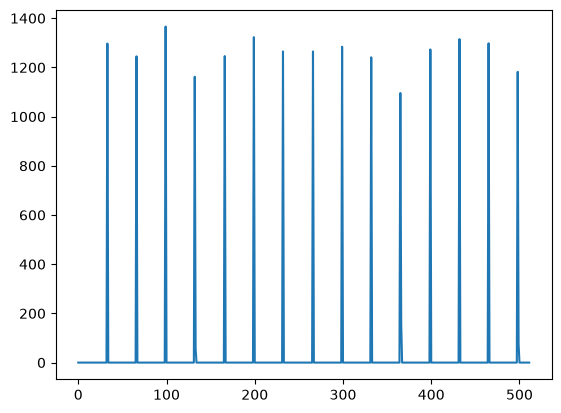

In [98]:
time_cal_2 = get_data(time_cal_path_2, TOTAL_CHANNELS_2)
plt.plot(time_cal_2["data"])
plt.show()

In [99]:
def get_time_cal(data_dict, time_cal_dict, period, degree):

  # convert data and time_cal to numpy arrays
  time_cal = np.array(time_cal_dict["data"])

  # keep only the tallest channel within +-10 channels of each peak
  original = time_cal.copy()   # compare against untouched counts
  for i in range(len(original)):
    if original[i] > 0:
      lo, hi = max(i - 10, 0), min(i + 11, len(original))
      if i != lo + np.argmax(original[lo:hi]):
        time_cal[i] = 0

  # assign 1 to any element that is non zero
  binary_peaks = np.zeros_like(time_cal)
  binary_peaks[time_cal > 0] = 1

  # # the first peak should be 2
  # binary_peaks[np.where(binary_peaks >0 )[0][0]] = 2

  # set each non zero entry to the sum of all before it
  cumulative_peaks = np.cumulative_sum(binary_peaks)
  step_array = cumulative_peaks.astype(np.float64)

  # set regions that are not peaks in raw calibration data to 0.0
  step_array[binary_peaks == 0] = 0.0

  # multiply all nonzero entries by the calibration period
  step_array *= period

  # get just the peaks and their indexes to fit
  peak_indexes = np.where(step_array > 0)[0]
  step_array = step_array[peak_indexes]

  # fit the steps by channel using polyfit
  fit_steps, cov = np.polyfit(peak_indexes, step_array, degree, cov=True)

  # print(np.sqrt(cov[0, 0]))

  return fit_steps, step_array, binary_peaks


In [100]:
def get_time_from_channel_linear(channel, fit_steps):
  return fit_steps[0] * channel + fit_steps[1]

In [101]:
def get_channel_from_time_linear(time, fit_steps):
  return int(np.divide(time - fit_steps[1], fit_steps[0]).round())

In [102]:
def get_time_fit(dict_data, time_cal_dict, show_plot = False):

  time_fit_param, step_array, binary_peaks = get_time_cal(dict_data, time_cal_dict, period = 1.28, degree = 1)
  peak_channels = np.where(binary_peaks > 0)[0]

  time_fit = get_time_from_channel_linear(peak_channels, time_fit_param)

  if show_plot:
    plt.plot(binary_peaks)
    plt.show()

    plt.scatter(peak_channels, step_array, marker = 'o')
    plt.plot(peak_channels, time_fit )
    plt.xlabel("Channel")
    plt.ylabel(f"Time ({mu}s)")
    plt.annotate( f"t = {time_fit_param[0] : .4f} * x - {abs(time_fit_param[1]): .4f}", (max(peak_channels)*.2, 15.5), fontsize=11) # top left annotate the fit equation
    plt.show()

  return time_fit_param

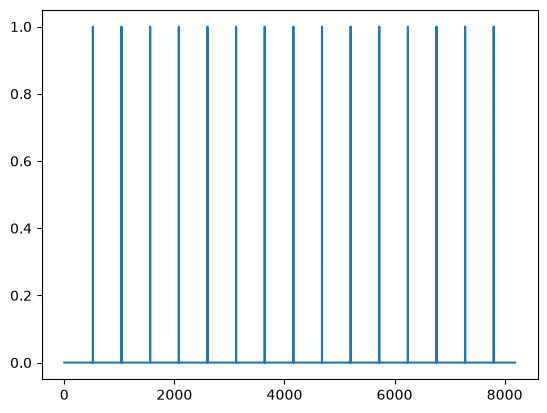

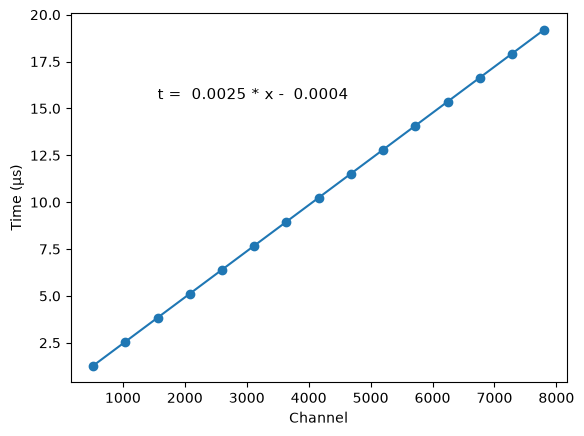

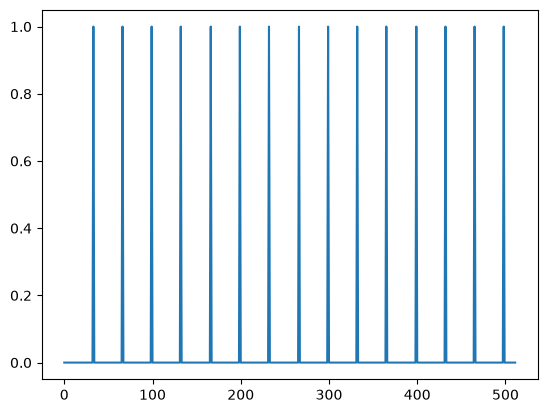

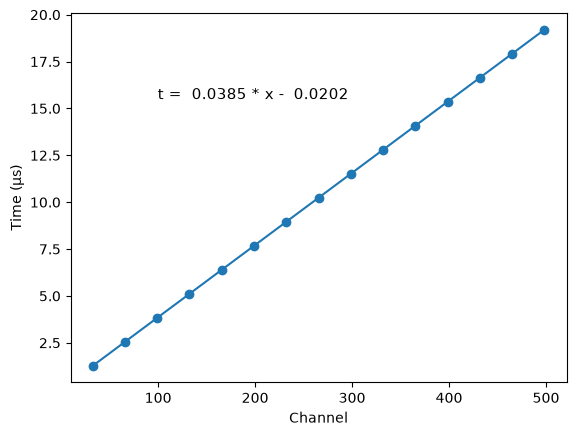

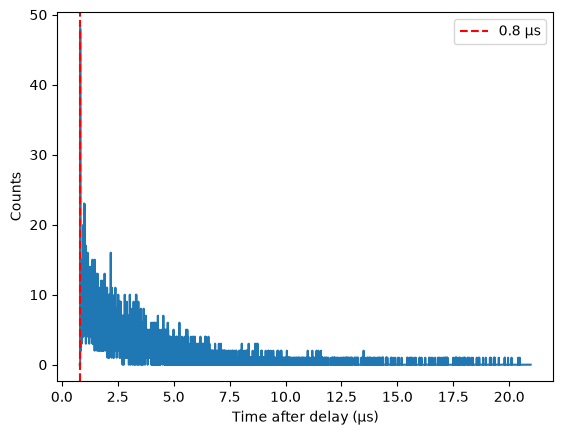

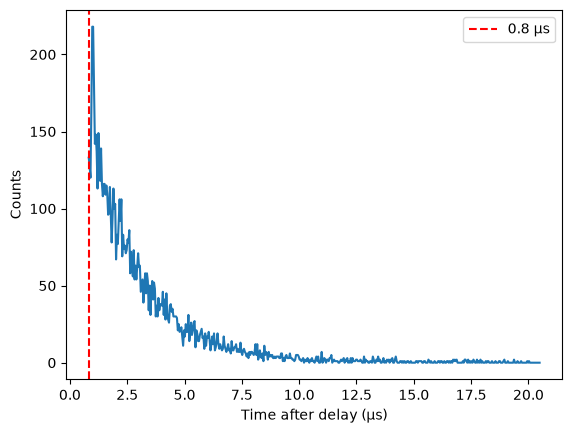

In [103]:
time_fit_param = get_time_fit(data_dict, time_cal_1, show_plot = True)
time_fit_param_512 = get_time_fit(rebinned_data_dict, time_cal_2, show_plot = True)


# plot the data vs time
channel_range = np.arange(len(data_dict["data"]))
channel_range_512 = np.arange(len(rebinned_data_dict["data"]))

time_range = get_time_from_channel_linear(channel_range, time_fit_param)
time_range_512 = get_time_from_channel_linear(channel_range_512, time_fit_param_512)

time_range_delayed = time_range + T_DELAY_US
time_range_512_delayed = time_range_512 + T_DELAY_US


plt.plot(time_range_delayed, data_dict["data"] )
plt.xlabel(f"Time after delay ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

plt.plot(time_range_512_delayed, rebinned_data_dict["data"] )
plt.xlabel(f"Time after delay ({mu}s)")
plt.ylabel("Counts")
plt.axvline(time_range_512_delayed[0], color='r', linestyle='--', label = f"0.8 {mu}s")
plt.legend()
plt.show()

# delay_in_channels = get_channel_from_time_linear(T_DELAY, time_fit_param)

# # fill zeros in data for the delay
# zeros = np.zeros(delay_in_channels)
# data_copy = data["data"].copy()
# delayed_data = np.concatenate((zeros, data_copy))

# # the delay has has extended the time range, extend the time range by the delay
# channel_range = np.arange(len(delayed_data))
# delayed_time_range = get_time_from_channel_linear(channel_range, time_fit_param)


# # shifted_time = time_range + T_delay
# plt.plot(delayed_time_range, delayed_data )
# plt.xlabel("Time difference (us)")
# plt.ylabel("Counts")
# plt.xlim(1.05, 5)
# plt.show()



# Data Fitting

In [104]:
def exp_func(t, N_0, tau, C):
  return N_0 * np.exp(-t/tau) + C

In [105]:
def expected_cnts_exp_func(t, N_0, tau, C):
  return (N_0 * np.exp(-t/tau) + C) * 0.01968703346961697

In [106]:
def exp_func_w_O(t, N_0, tau, C):
  return (N_0 * (np.exp(-t/tau) + .26 * np.exp(-t/1.795)) + C)* 0.0024608791837021217

In [107]:
def exp_func_w_O_Si(t, N_0, tau, C):
  # return (N_0 * (np.exp(-t/tau) + .26 * np.exp(-t/1.795) + 0.19*np.exp(-t/0.756)) + C )* 0.0024608791837021217
  # return (N_0 * (np.exp(-t/tau) + .26 * np.exp(-t/1.795) + 0.19*np.exp(-t/0.756)) + C )* 0.01968703346961697
  return (N_0 * (np.exp(-t/tau) + .26 * np.exp(-t/1.795) + 0.19*np.exp(-t/0.756)) + C )* 0.0385

In [108]:
def fit_exp_dist(data, start_channel, end_channel, time_fit_parameters, bw):

  x_data = np.arange(start_channel, end_channel + 1)
  x_time = get_time_from_channel_linear(x_data, time_fit_parameters)
  y_data = data[start_channel: end_channel + 1]


  # popt, pcov = opt.curve_fit(exp_func, x_time, y_data, p0=intial_guess, absolute_sigma = True)

  ############## iteratively reweighted least squares (IRLS) ##############

  p0 = [max(y_data[:20].mean(), 1)/bw*np.exp(x_time[0]/2.2),   # rate scaled back to t = 0
          2.2, max(y_data[-200:].mean()/bw, 0.1)]
  lo, hi = [0, 0.5, 0], [np.inf, 5.0, np.inf]              # N_0 ≥ 0, 0.5 < tau < 5, C ≥ 0

  # Step 0: rough weights from the data, just to get a starting point
  p = opt.curve_fit(expected_cnts_exp_func, x_time, y_data, p0=p0, sigma=np.sqrt(np.maximum(y_data, 1)), bounds=(lo, hi))[0]

  # Steps 1+: weights from the model, refit until stable
  for i in range(10):
      sigma = np.sqrt(np.maximum(expected_cnts_exp_func(x_time, *p), 1e-6))  # sqrt of expected counts; floor avoids /0
      p_new, cov = opt.curve_fit(expected_cnts_exp_func, x_time, y_data, p0=p, sigma=sigma, absolute_sigma=True, bounds=(lo, hi))
      err = np.sqrt(np.diag(cov))
      converged = np.all(np.abs(p_new - p) < 1e-4*err)   # change much smaller than the error
      p = p_new
      if converged:
          break

  fit_N_0, fit_tau, fit_C = p

  tau_err = err[1]
  mu = expected_cnts_exp_func(x_time, *p)

  print(f"tau error: {tau_err}")

  fit_y_data = expected_cnts_exp_func(x_time, fit_N_0, fit_tau, fit_C)

  redux_chi2 = np.sum((y_data - mu)**2 / mu) / (len(y_data) - 3)

  print(f"reduced chi squared: {redux_chi2}")

  return fit_y_data, fit_N_0, fit_tau, fit_C, tau_err

In [109]:
def fit_exp_dist_w_oxy(data, start_channel, end_channel, time_fit_parameters, bw):

  x_data = np.arange(start_channel, end_channel + 1)
  x_time = get_time_from_channel_linear(x_data, time_fit_parameters)
  y_data = data[start_channel: end_channel + 1]


  # popt, pcov = opt.curve_fit(exp_func, x_time, y_data, p0=intial_guess, absolute_sigma = True)

  ############## iteratively reweighted least squares (IRLS) ##############

  p0 = [max(y_data[:20].mean(), 1)/bw*np.exp(x_time[0]/2.2),   # rate scaled back to t = 0
          2.2, max(y_data[-200:].mean()/bw, 0.1)]
  lo, hi = [0, 0.5, 0], [np.inf, 5.0, np.inf]              # N_0 ≥ 0, 0.5 < tau < 5, C ≥ 0

  # Step 0: rough weights from the data, just to get a starting point
  p = opt.curve_fit(exp_func_w_O, x_time, y_data, p0=p0, sigma=np.sqrt(np.maximum(y_data, 1)), bounds=(lo, hi) )[0]

  # Steps 1+: weights from the model, refit until stable
  for i in range(10):
      sigma = np.sqrt(np.maximum(exp_func_w_O(x_time, *p), 1e-6))  # sqrt of expected counts; floor avoids /0
      p_new, cov = opt.curve_fit(exp_func_w_O, x_time, y_data, p0=p, sigma=sigma, absolute_sigma=True, bounds=(lo, hi))
      err = np.sqrt(np.diag(cov))
      converged = np.all(np.abs(p_new - p) < 1e-8*err)   # change much smaller than the error
      p = p_new
      if converged:
          break

  fit_N_0, fit_tau, fit_C = p

  tau_err = err[1]
  mu = exp_func_w_O(x_time, *p)

  print(f"tau error: {tau_err}")

  fit_y_data = exp_func_w_O(x_time, fit_N_0, fit_tau,  fit_C)

  redux_chi2 = np.sum((y_data - mu)**2 / mu) / (len(y_data) - 3)
  print(f"reduced chi squared: {redux_chi2}")

  return fit_y_data, fit_N_0, fit_tau , fit_C, tau_err

In [110]:
def fit_exp_dist_w_oxy_Si(data, start_channel, end_channel, time_fit_parameters, bw):

  x_data = np.arange(start_channel, end_channel + 1)
  x_time = get_time_from_channel_linear(x_data, time_fit_parameters)
  y_data = data[start_channel: end_channel + 1]


  # popt, pcov = opt.curve_fit(exp_func, x_time, y_data, p0=intial_guess, absolute_sigma = True)

  ############## iteratively reweighted least squares (IRLS) ##############

  p0 = [max(y_data[:20].mean(), 1)/bw*np.exp(x_time[0]/2.2),   # rate scaled back to t = 0
          2.2, max(y_data[-200:].mean()/bw, 0.1)]
  lo, hi = [0, 0.5, 0], [np.inf, 5.0, np.inf]              # N_0 ≥ 0, 0.5 < tau < 5, C ≥ 0


  # Step 0: rough weights from the data, just to get a starting point
  p = opt.curve_fit(exp_func_w_O_Si, x_time, y_data, p0=p0, sigma=np.sqrt(np.maximum(y_data, 1)), bounds=(lo, hi))[0]

  # Steps 1+: weights from the model, refit until stable
  for i in range(10):
      sigma = np.sqrt(np.maximum(exp_func_w_O_Si(x_time, *p), 1e-6))  # sqrt of expected counts; floor avoids /0
      p_new, cov = opt.curve_fit(exp_func_w_O_Si, x_time, y_data, p0=p, sigma=sigma, absolute_sigma=True, bounds=(lo, hi))
      err = np.sqrt(np.diag(cov))
      converged = np.all(np.abs(p_new - p) < 1e-5*err)   # change much smaller than the error
      p = p_new
      if converged:
          break

  fit_N_0, fit_tau, fit_C = p

  tau_err = err[1]
  mu = exp_func_w_O_Si(x_time, *p)

  print(f"tau error: {tau_err}")

  fit_y_data = exp_func_w_O_Si(x_time, fit_N_0, fit_tau,  fit_C)

  redux_chi2 = np.sum((y_data - mu)**2 / mu) / (len(y_data) - 3)

  print(f"reduced chi squared: {redux_chi2}")

  return fit_y_data, fit_N_0, fit_tau , fit_C, tau_err

tau error: 0.0412080960384041
reduced chi squared: 1.0655808778279119
2.294265654506856


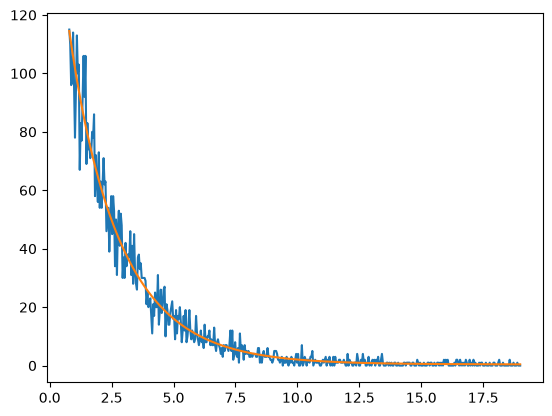

tau error: 0.04304553455498893
reduced chi squared: 1.0686474399960548
2.282563761739985
change in tau: -0.011701892766871058
change in tau error:  0.001837
sigma difference:  0.012442
delta tau over sigma diff 0.940492624265834


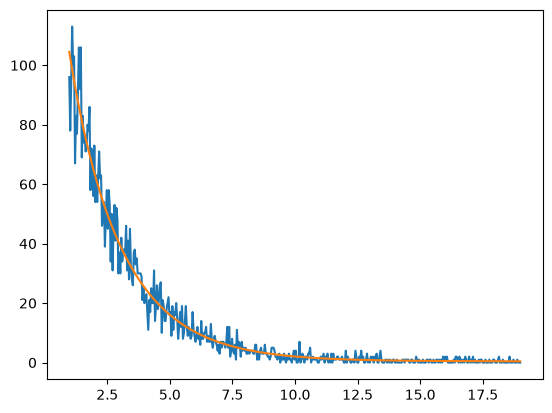

tau error: 0.04892993370571454
reduced chi squared: 1.0298522881836076
2.2725368767655247
change in tau: -0.010026884974460248
change in tau error:  0.005884
sigma difference:  0.023264
delta tau over sigma diff 0.43100168399102784


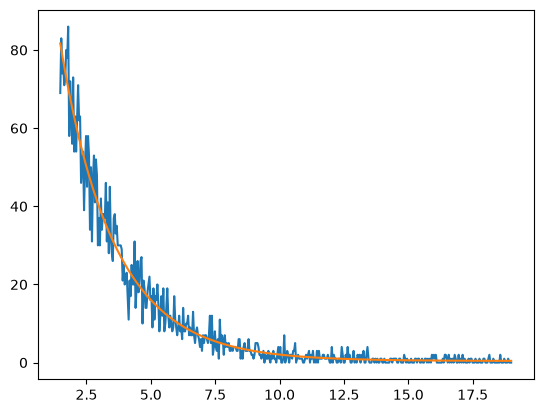

tau error: 0.05564614609898423
reduced chi squared: 1.0349624557592967
2.2579324003524928
change in tau: -0.014604476413031975
change in tau error:  0.006716
sigma difference:  0.026502
delta tau over sigma diff 0.5510710570674295


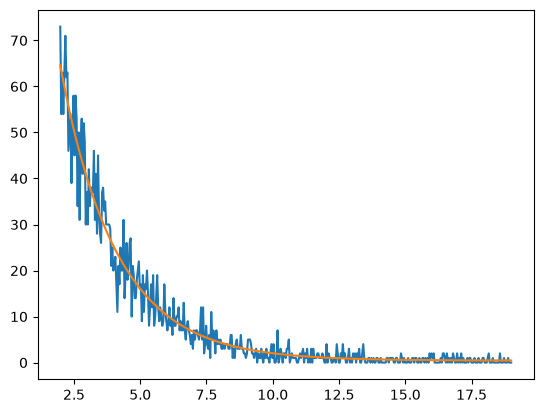

tau error: 0.06349569564639769
reduced chi squared: 1.036072272529601
2.243827584844437
change in tau: -0.014104815508055868
change in tau error:  0.007850
sigma difference:  0.030581
delta tau over sigma diff 0.4612250511546436


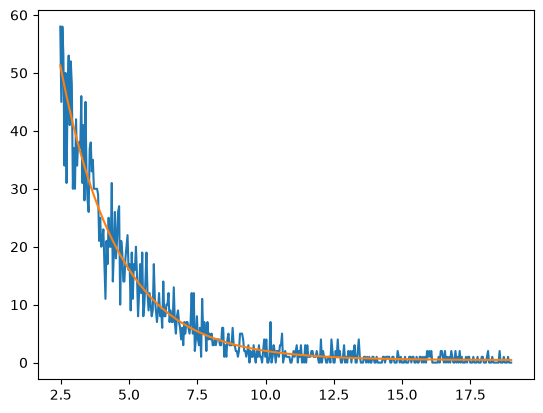

tau error: 0.07336536663710086
reduced chi squared: 1.01980982905201
2.246260939084899
change in tau: 0.0024333542404622044
change in tau error:  0.009870
sigma difference:  0.036753
delta tau over sigma diff 0.06620854528284213


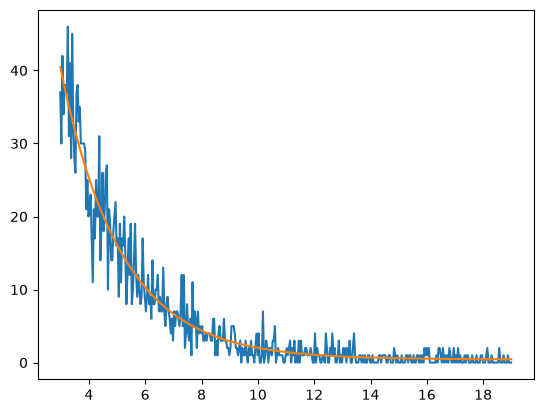

tau error: 0.08540338871530136
reduced chi squared: 1.019968467905255
2.2547047922732486
change in tau: 0.008443853188349504
change in tau error:  0.012038
sigma difference:  0.043718
delta tau over sigma diff 0.19314371736595237


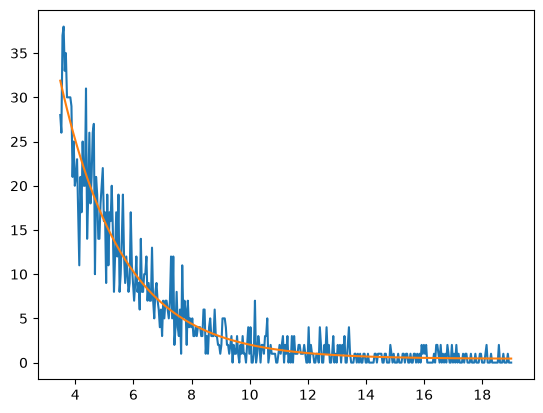

tau error: 0.10281634104057955
reduced chi squared: 1.0324208954809555
2.3224495869679584
change in tau: 0.06774479469470984
change in tau error:  0.017413
sigma difference:  0.057249
delta tau over sigma diff 1.1833334814721905


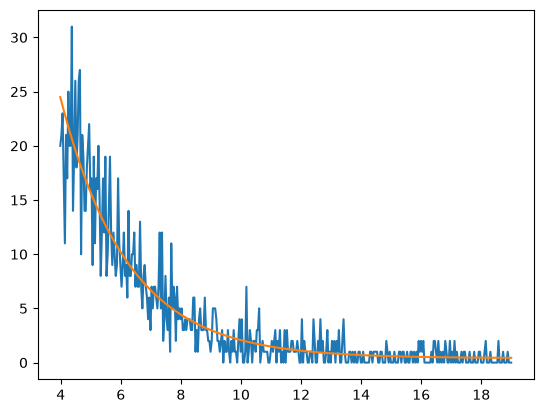

In [111]:
data_dict = get_data(data_path, TOTAL_CHANNELS)
time_cal_dict = get_data(time_cal_path_2, TOTAL_CHANNELS_2)


y_data = data_dict["data"]
y_data_rebinned = rebin_histogram(y_data, 512)

rebinned_data_dict = data_dict.copy()
rebinned_data_dict['data'] = y_data_rebinned


time_fit_param, step_array, binary_peaks = get_time_cal(rebinned_data_dict, time_cal_dict, period = 1.28, degree = 1)

m = time_fit_param[0]
b = time_fit_param[1]

starts = []
for start_time in [0.8,1,1.5,2,2.5, 3, 3.5, 4]:
  start_channel = get_channel_from_time_linear(start_time, time_fit_param)
  starts.append(start_channel)
end_channel= get_channel_from_time_linear(19, time_fit_param)


last_tau = 0
last_tau_err = 0
for start_channel in starts:
  fit_y_data, fit_N_0, fit_tau, fit_C, fit_tau_err = fit_exp_dist_w_oxy_Si(y_data_rebinned, start_channel, end_channel, time_fit_param, m)
  print(fit_tau)

  if last_tau != 0:
    delta_tau = fit_tau - last_tau
    print(f"change in tau: {delta_tau}")

  last_tau = fit_tau


  if last_tau_err != 0:
    print(f"change in tau error: {fit_tau_err - last_tau_err : .6f}")
    sigma_diff = np.sqrt(np.square(fit_tau_err) - np.square(last_tau_err))
    print(f"sigma difference: {sigma_diff : .6f}")

  if last_tau != 0 and last_tau_err != 0:
    print(f'delta tau over sigma diff {abs(delta_tau)/sigma_diff}')

  last_tau_err = fit_tau_err

  x_data = np.arange(start_channel, end_channel + 1)
  x_time = get_time_from_channel_linear(x_data, time_fit_param)

  plt.plot(x_time, y_data_rebinned[start_channel: end_channel + 1])
  plt.plot(x_time, fit_y_data)
  plt.show()

# Combining data sets

In [112]:
# data_path_1 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest.Spe"
# data_path_2 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest2.Spe"
# data_path_3 = r"/content/drive/MyDrive/ADVLAB/Muon-Lifetime/Data/MuonTest3.Spe"

# data_paths = [data_path_1,data_path_2, data_path_3]

# all_data = None
# for path in data_paths:
#   # y_data = get_data(data_path, TOTAL_CHANNELS)["data"]
#   # y_data = np.array(y_data)

#   if all_data is None:
#     all_data = y_data
#   else:
#     all_data += y_data

# plt.plot(all_data)

# Hourly Counts

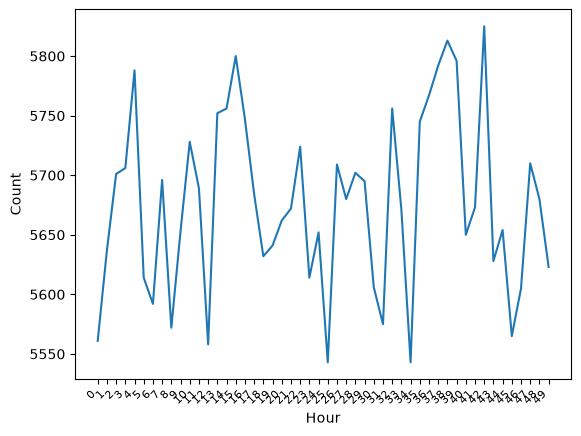

In [113]:
counts = []
timestamps = []
for file in sorted(os.listdir(hourly_folder_path)):
  if file.endswith(".Spe"):
    data_path = os.path.join(hourly_folder_path, file)
    data_dict = get_data(data_path, TOTAL_CHANNELS)

    timestamp = f"{data_dict['start_date']} {data_dict['start_time']}"
    timestamps.append(timestamp)

    y_data = data_dict["data"]
    count = sum(y_data)
    counts.append(count)

hours = [f"{i}" for i in range(len(counts))]

plt.plot(hours, counts)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.xlabel("Hour")
plt.ylabel("Count")
plt.show()

In [114]:
count_data = pd.DataFrame({"timestamp": timestamps, "count": counts})

#convert to datetime round to the nearest hour
count_data['timestamp'] = pd.to_datetime(count_data['timestamp'])
count_data['timestamp'] = count_data['timestamp'].dt.round('h')

met_data = pd.read_csv(r"C:\pyt\ADV-Lab\muon-lifetime\ATT.csv", parse_dates=["valid"])
met_columns = ['valid','tmpf','alti']
met_data = met_data[met_columns]

# round the valid column to the nearest hour
met_data['valid'] = met_data['valid'].dt.round('h')

merged = met_data.merge(count_data, how='inner', left_on='valid', right_on='timestamp').drop(columns = ['valid'])
merged

,tmpf,alti,timestamp,count
0,59.0,30.03,2026-11-13 01:00:00,5689
1,58.0,30.03,2026-11-13 02:00:00,5558
2,56.0,30.02,2026-11-13 03:00:00,5752
3,55.0,30.02,2026-11-13 04:00:00,5756
4,56.0,30.02,2026-11-13 05:00:00,5800
5,56.0,30.02,2026-11-13 06:00:00,5747
6,54.0,30.04,2026-11-13 07:00:00,5684
7,56.0,30.05,2026-11-13 08:00:00,5632
8,61.0,30.06,2026-11-13 09:00:00,5641
9,65.0,30.07,2026-11-13 10:00:00,5662


array([[<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>],
       [<Axes: xlabel='timestamp'>]], dtype=object)

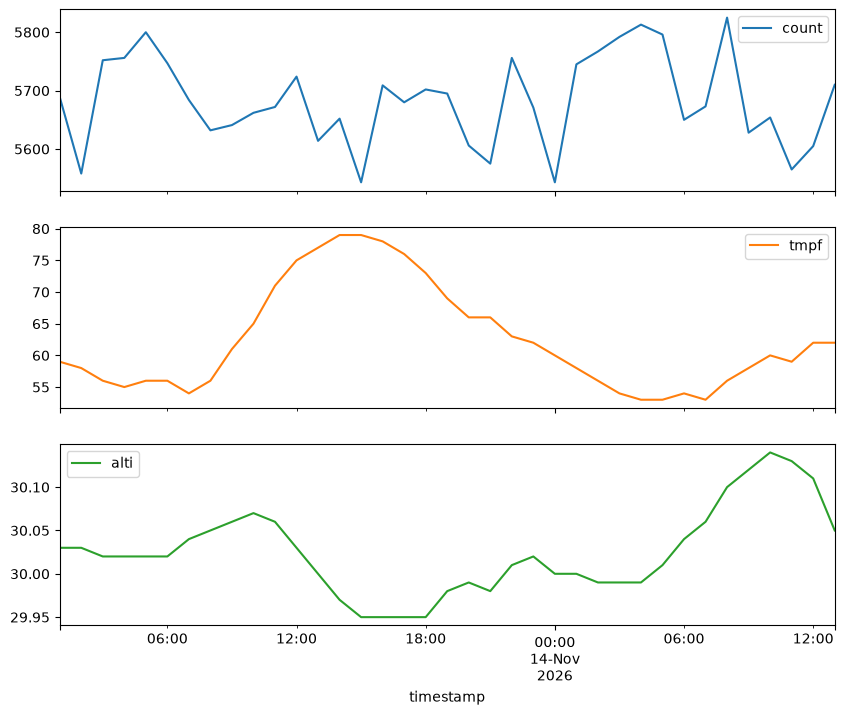

In [115]:
merged.plot(x='timestamp', y=['count', 'tmpf', 'alti'], subplots=True, layout=(3, 1), figsize=(10, 8))

In [116]:
# Check how muon counts correlate with temperature and altitude
merged[['count', 'tmpf', 'alti']].corr()

,count,tmpf,alti
count,1.000000,-0.350807,-0.124347
tmpf,-0.350807,1.000000,-0.448686
alti,-0.124347,-0.448686,1.000000


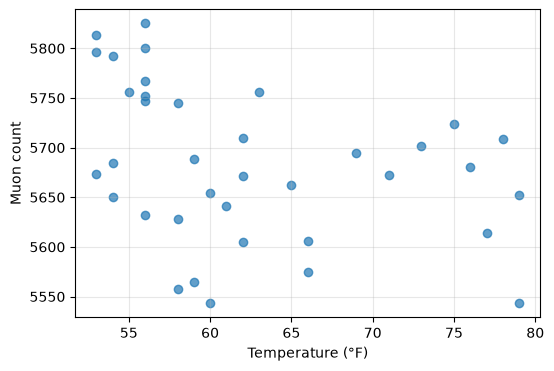

In [117]:
# Scatter plot of muon count vs. temperature from the merged dataset
plt.figure(figsize=(6, 4))
plt.scatter(merged['tmpf'], merged['count'], alpha=0.7)
plt.xlabel('Temperature (°F)')
plt.ylabel('Muon count')
plt.grid(True, alpha=0.3)
plt.show()

In [118]:
valid = merged[['tmpf', 'count']].dropna()
slope, intercept = np.polyfit(valid['tmpf'], valid['count'], 1)
r = np.corrcoef(valid['tmpf'], valid['count'])[0, 1]

print(f"Slope: {slope:.4f} counts per °F")
print(f"Intercept: {intercept:.2f}")
print(f"R²: {r**2:.4f}")

Slope: -3.2825 counts per °F
Intercept: 5888.16
R²: 0.1231


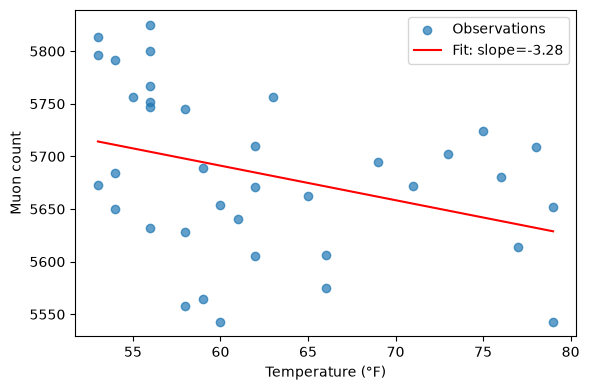

In [119]:
x_line = np.linspace(valid['tmpf'].min(), valid['tmpf'].max(), 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(6, 4))
plt.scatter(valid['tmpf'], valid['count'], alpha=0.7, label='Observations')
plt.plot(x_line, y_line, color='red', label=f'Fit: slope={slope:.2f}')
plt.xlabel('Temperature (°F)')
plt.ylabel('Muon count')
plt.legend()
plt.tight_layout()
plt.show()

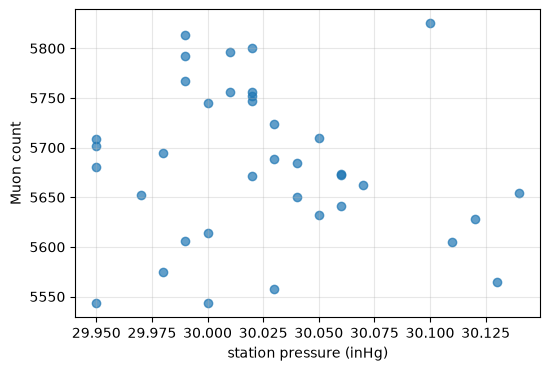

In [120]:
# scatter plot of muon count vs. altitude from the merged dataset
plt.figure(figsize=(6, 4))
plt.scatter(merged['alti'], merged['count'], alpha=0.7)
plt.xlabel('station pressure (inHg)')
plt.ylabel('Muon count')
plt.grid(True, alpha=0.3)
plt.show()

In [121]:
# Fit a linear trend and compute correlation for muon count vs. altitude
valid_alt = merged[['alti', 'count']].dropna()
slope_alt, intercept_alt = np.polyfit(valid_alt['alti'], valid_alt['count'], 1)
r_alt = np.corrcoef(valid_alt['alti'], valid_alt['count'])[0, 1]

print(f"Slope: {slope_alt:.4f} counts per inHg")
print(f"Intercept: {intercept_alt:.2f}")
print(f"Pearson r: {r_alt:.4f}")

Slope: -192.8435 counts per inHg
Intercept: 11473.56
Pearson r: -0.1243


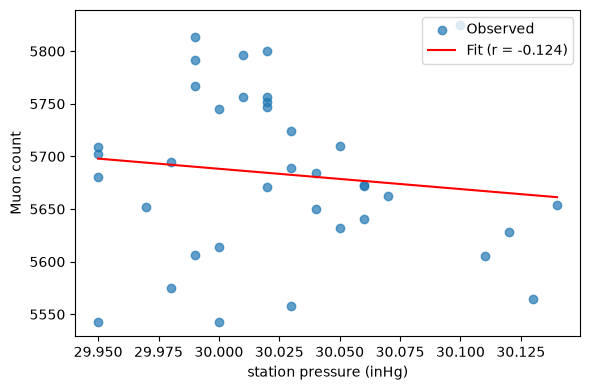

In [122]:
# Plot muon count vs. altitude with the fitted linear trend
x_line_alt = np.linspace(valid_alt['alti'].min(), valid_alt['alti'].max(), 100)
y_line_alt = slope_alt * x_line_alt + intercept_alt

plt.figure(figsize=(6, 4))
plt.scatter(valid_alt['alti'], valid_alt['count'], alpha=0.7, label='Observed')
plt.plot(x_line_alt, y_line_alt, color='red', label=f'Fit (r = {r_alt:.3f})')
plt.xlabel('station pressure (inHg)')
plt.ylabel('Muon count')
plt.legend()
plt.tight_layout()
plt.show()

In [132]:
import statsmodels.api as sm

def design_matrix(df, p_col="p_station_hPa", extra_cols=()):
    """Columns: constant, centered pressure, and any extra centered regressors."""
    X = pd.DataFrame({"const": 1.0, "dP": df[p_col] - df[p_col].mean()},
                     index=df.index)
    for c in extra_cols:
        X["d_" + c] = df[c] - df[c].mean()
    return X

def fit_glm(df, count_col="counts", time_col="real_s",
            p_col="p_station_hPa", extra_cols=()):

    X = design_matrix(df, p_col, extra_cols)
    model = sm.GLM(df[count_col], X, family=sm.families.Poisson(),
                   offset=np.log(df[time_col]))
    res = model.fit()

    # Pearson chi2/dof ~ 1 for pure Poisson scatter. If clearly > 1,
    # use res_scaled, whose errors are inflated by sqrt(chi2/dof).
    chi2_dof = res.pearson_chi2 / res.df_resid
    res_scaled = model.fit(scale="X2")
    return res, res_scaled, chi2_dof

def report(res, res_scaled, chi2_dof):
    b, e, es = res.params, res.bse, res_scaled.bse
    print(f"rate at mean P : {np.exp(b['const']):.4f} Hz")
    print(f"beta           : {100*b['dP']:+.4f} ± {100*e['dP']:.4f} %/hPa"
          f"   (scaled errors: ± {100*es['dP']:.4f})")
    for name in b.index[2:]:
        print(f"{name:15s}: {100*b[name]:+.4f} ± {100*e[name]:.4f} %/unit")
    print(f"Pearson chi2/dof: {chi2_dof:.3f}  (dof = {int(res.df_resid)})")


def plot_fit(df, res, count_col="counts", time_col="real_s",
             p_col="p_station_hPa"):
    import matplotlib.pyplot as plt

    rate = df[count_col] / df[time_col]
    err = np.sqrt(df[count_col]) / df[time_col]
    mu = res.fittedvalues
    pull = (df[count_col] - mu) / np.sqrt(mu)

    fig, ax = plt.subplots(2, 1, figsize=(7, 7))
    ax[0].errorbar(df[p_col], rate, err, fmt="o", ms=3, alpha=0.5)
    pp = np.linspace(df[p_col].min(), df[p_col].max(), 100)
    b = res.params
    ax[0].plot(pp, np.exp(b["const"] + b["dP"] * (pp - df[p_col].mean())), "r-")
    ax[0].set(xlabel="Station pressure (hPa)", ylabel="Rate (Hz)")

    ax[1].plot(df.index, pull, ".")
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set(xlabel="Window start (UTC)", ylabel="Residual (σ)")
    fig.tight_layout()
    plt.show()

rate at mean P : 303.3455 Hz
beta           : -270.5977 ± 4.4233 %/hPa   (scaled errors: ± 373.1856)
d_tmpf         : +0.3998 ± 0.0298 %/unit
Pearson chi2/dof: 7117.917  (dof = 34)


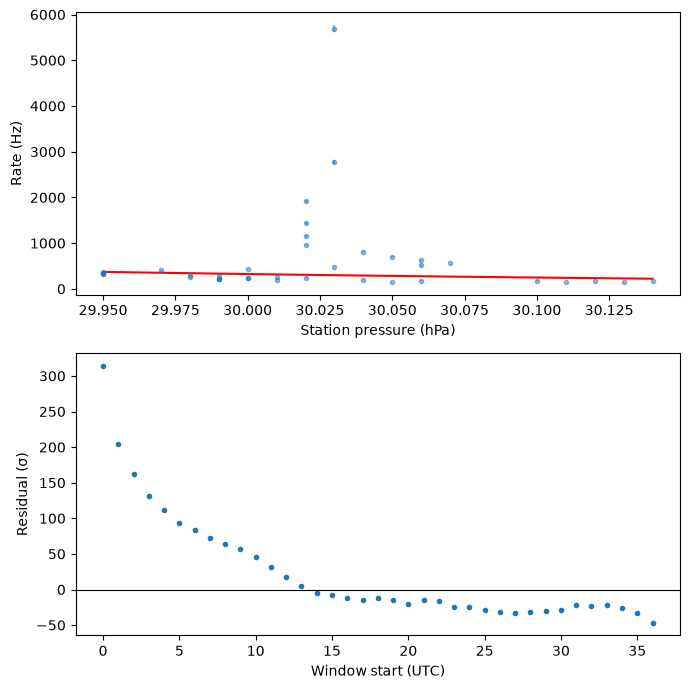

In [136]:
# change timestamp column to hours
df = merged.copy()
df['hour'] = [i for i in range(1, len(df['count']) + 1)]

# res, res_scaled, chi2_dof = fit_glm(df, count_col = 'count', time_col = 'hour', p_col = 'alti')                            # pressure only
res, res_scaled, chi2_dof = fit_glm(df, count_col = 'count', time_col = 'hour', p_col = 'alti', extra_cols=["tmpf"])     # + temperature term
report(res, res_scaled, chi2_dof)
plot_fit(df, res, count_col = 'count', time_col = 'hour', p_col = 'alti')    # rate vs pressure with the fit line, and residuals vs time